# Eye Cleaning Pipeline Validation

Geoff originally developed a matlab routine (`processEyeData.m`) located in `/matlabCode` with the help of Gemini to clean the eye data of both the raw Neon recording as well as the output
gaze positions of the egocentric video mapper. Zach then used GPT 6.1 Astra light to initially translate this into Python. After the initial translation was in place, Zach went through the code to validate correctness, readability, and design. This notebook serves as a validation of the performance between MATLAB and Python to ensure both pipeline's return the same results given the same inut.

We choose a small subset of test subjects and activities to run throug hboth pipelines. Note that the MATLAB engine requires Signal Processing Toolbox and to access these recordings, the GKALabNAS must be mounted.

For path purposes, this notebook assumes you are running it from the `analyzeEyeTracking` directory


## 1. Paths and settings

Choose the recordings here.


In [1]:
%matplotlib inline

import os
import tempfile
import shutil
from pathlib import Path
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
import matlab.engine

import pythonCode.cleanEyeTracking as python_pipeline

# Paths to the RAW and PROCESSED recording directories
raw_recording_root: Path = Path("/Volumes/FLIC_raw/NEWscriptedIndoorOutdoorVideos2026")
mapped_recording_root: Path = Path("/Volumes/FLIC_processing/NEWscriptedIndoorOutdoorVideos2026")

# Use every combination of subject and activity listed here.
subject_ids: tuple[int, ...] = (2001, 2002, 2003)
activity_names: tuple[str, ...] = ("chat", "walkIndoor", "walkOutdoor")



## 2. Find the input CSVs

Each recording needs `3d_eye_states.csv`, `blinks.csv`, and `alternative_camera_gaze.csv`. Stop if a recording is missing. 


In [2]:
def get_directory_names(parent_directory: Path) -> list[str]:
    """Return the names of directories directly inside the given path."""
    directory_names: list[str] = []

    for entry_name in os.listdir(parent_directory):
        entry_path: Path = parent_directory / entry_name

        if entry_path.is_dir():
            directory_names.append(entry_name)

    return directory_names


# Construct a list of dictionaries, each containing the recording name "subject_activity", 
# and path to its raw and processed csv folders 
recordings: list[dict] = []

# Iterate through the chosen subject ids 
for subject_id in sorted(subject_ids):

    # Iterate through the chosen activities
    for activity_name in sorted(activity_names):

        # Construct the paths to the folders
        recording_name: str = f"FLIC_{subject_id}_{activity_name}"
        recording_path: Path = Path(f"FLIC_{subject_id}") / activity_name
        raw_neon_folder: Path = raw_recording_root / recording_path / "Neon"
        mapped_neon_folder: Path = mapped_recording_root / recording_path / "Neon"

        # Both exports have a recording folder named 1 below Neon.
        # NOTE: Test subjects (2001-2006) ONLY have a 1. It's possible other subjects 
        # have other recordings and the first is not the intended recording
        raw_csv_folder: Path = raw_neon_folder / "1"
        mapped_csv_folder: Path = mapped_neon_folder / "1"
        
        if subject_id not in range(2001, 2007):
            warnings.warn("Subject ID not in test subjects. Default is first recording, check if this is the intended directory")

        # Find the first named directory below the raw recording folder.
        raw_directory_names: list[str] = get_directory_names(raw_csv_folder)

        raw_csv_folder = raw_csv_folder / raw_directory_names[0]

        # Raw CSVs are one more directory below the first named folder.
        raw_export_directory_names: list[str] = get_directory_names(raw_csv_folder)
        raw_csv_folder = raw_csv_folder / raw_export_directory_names[0]

        # Processed CSVs are directly inside this single mapper-results folder.
        mapped_csv_folder = mapped_csv_folder / "egocentric_mapper_results"

        # Store the two input folders together so both implementations use the
        # same recording later.
        recordings.append(
            {
                "recording_name": recording_name,
                "raw_csv_folder": raw_csv_folder,
                "mapped_csv_folder": mapped_csv_folder,
            }
        )

# Require all requested subject/activity pairs before reporting agreement.
expected_recording_count: int = len(subject_ids) * len(activity_names)
assert recordings, "No recordings selected."
assert len(recordings) == expected_recording_count, "Recording selection is incomplete."

display(pd.DataFrame(recordings))


,recording_name,raw_csv_folder,mapped_csv_folder
0,FLIC_2001_chat,/Volumes/FLIC_raw/NEWscriptedIndoorOutdoorVide...,/Volumes/FLIC_processing/NEWscriptedIndoorOutd...
1,FLIC_2001_walkIndoor,/Volumes/FLIC_raw/NEWscriptedIndoorOutdoorVide...,/Volumes/FLIC_processing/NEWscriptedIndoorOutd...
2,FLIC_2001_walkOutdoor,/Volumes/FLIC_raw/NEWscriptedIndoorOutdoorVide...,/Volumes/FLIC_processing/NEWscriptedIndoorOutd...
3,FLIC_2002_chat,/Volumes/FLIC_raw/NEWscriptedIndoorOutdoorVide...,/Volumes/FLIC_processing/NEWscriptedIndoorOutd...
4,FLIC_2002_walkIndoor,/Volumes/FLIC_raw/NEWscriptedIndoorOutdoorVide...,/Volumes/FLIC_processing/NEWscriptedIndoorOutd...
5,FLIC_2002_walkOutdoor,/Volumes/FLIC_raw/NEWscriptedIndoorOutdoorVide...,/Volumes/FLIC_processing/NEWscriptedIndoorOutd...
6,FLIC_2003_chat,/Volumes/FLIC_raw/NEWscriptedIndoorOutdoorVide...,/Volumes/FLIC_processing/NEWscriptedIndoorOutd...
7,FLIC_2003_walkIndoor,/Volumes/FLIC_raw/NEWscriptedIndoorOutdoorVide...,/Volumes/FLIC_processing/NEWscriptedIndoorOutd...
8,FLIC_2003_walkOutdoor,/Volumes/FLIC_raw/NEWscriptedIndoorOutdoorVide...,/Volumes/FLIC_processing/NEWscriptedIndoorOutd...


## 3. Run MATLAB Code
The MATLAB script reads CSVs from its current folder. For each recording, make a temporary folder with copies of the original CSVs and run the script there, then remove the temporary files

In [3]:
# Start MATLAB and load the project so processEyeData is on its path.
eng = matlab.engine.start_matlab()

try:
    eng.tbUseProject('lightLoggerAnalysis', nargout=0)

    # Define a holder for results.
    matlab_results: dict[str, dict[str, np.ndarray]] = {}
    matlab_result_names: tuple[str, ...] = (
        "cleaned_data_matrix",
        "pupil_raw",
        "aperture_mean_raw",
        "aperture_diff_raw",
        "gaze_x_raw",
        "gaze_y_raw",
        "is_blink_raw",
    )

    # Keep MATLAB's figures hidden; the notebook displays the comparisons.
    eng.eval("set(groot, 'defaultFigureVisible', 'off');", nargout=0)

    for recording in recordings:
        recording_name: str = recording["recording_name"]

        # Bring this recording's CSVs together for the MATLAB eye cleaner.
        # Remove the folder as soon as its results have been copied into Python.
        with tempfile.TemporaryDirectory(prefix=recording_name + "TEMP_") as temporary_directory:
            matlab_input_folder: Path = Path(temporary_directory)

            # The script reads these filenames from its current directory.
            # Copy the files here so MATLAB reads local files rather than links
            # back to the mounted drive. The original CSVs stay unchanged.
            for filename, source_folder in (
                ("3d_eye_states.csv", recording["raw_csv_folder"]),
                ("blinks.csv", recording["raw_csv_folder"]),
                ("alternative_camera_gaze.csv", recording["mapped_csv_folder"]),
            ):
                source_csv: Path = source_folder / filename
                temporary_csv: Path = matlab_input_folder / filename
                shutil.copyfile(source_csv, temporary_csv)

            try:
                # Run the script on the project path with this recording's inputs.
                eng.cd(str(matlab_input_folder), nargout=0)
                eng.eval("processEyeData;", nargout=0)

                # Copy the MATLAB workspace arrays directly into notebook memory.
                recording_results: dict[str, np.ndarray] = {}
                for variable_name in matlab_result_names:
                    recording_results[variable_name] = np.array(eng.workspace[variable_name])

                matlab_results[recording_name] = recording_results
                eng.eval("close all force;", nargout=0)

            finally:
                # Leave the folder before it is removed, including on failure.
                eng.cd(str(Path.cwd()), nargout=0)

finally:
    # Release this MATLAB session even if a recording fails.
    eng.quit()


Locating project "lightLoggerAnalysis" within "/Users/zacharykelly/Documents/MATLAB/projects".
  Found at "/Users/zacharykelly/Documents/MATLAB/projects/lightLoggerAnalysis".


Local copy of ToolboxToolbox out of date (or you made local modifications).
Consider updating with git pull or otherwise synchronizing.



Updating "ToolboxRegistry".
Already up to date.
Updating "lightLoggerAnalysis".
Already up to date.
Updating "combiLEDToolbox".
Already up to date.
Updating "BrainardLabToolbox".
Already up to date.
Updating "WatsonYellott2012_PupilSize".
Already up to date.
Updating "bads".
Already up to date.
Updating "export_fig".
Already up to date.
Updating "Psychtoolbox-3".
Already up to date.
Updating "SilentSubstitutionToolbox".
Already up to date.
Updating "ExampleTestToolbox".
Already up to date.
Updating "isetcam".
Already up to date.
Updating "isetbio".
Already up to date.
Resetting path to factory state.
Adding "ToolboxToolbox" to path at "/Users/zacharykelly/Documents/MATLAB/ToolboxToolbox".
Adding "lightLoggerAnalysis" to path at "/Users/zacharykelly/Documents/MATLAB/projects/lightLoggerAnalysis".
Adding "combiLEDToolbox" to path at "/Users/zacharykelly/Documents/MATLAB/toolboxes/combiLEDToolbox/code".
Adding "BrainardLabToolbox" to path at "/Users/zacharykelly/Documents/MATLAB/toolboxes

  Local hook template more recent than local hook. Consider updating.


  Running local hook "/Users/zacharykelly/Documents/MATLAB/localHookFolder/lightLoggerAnalysisLocalHook.m".
Locating project "lightLoggerAnalysis" within "/Users/zacharykelly/Documents/MATLAB/projects".
  Found at "/Users/zacharykelly/Documents/MATLAB/projects/lightLoggerAnalysis".
Locating project "lightLogger" within "/Users/zacharykelly/Documents/MATLAB/projects".
  Found at "/Users/zacharykelly/Documents/MATLAB/projects/lightLogger".
Locating project "combiExperiments" within "/Users/zacharykelly/Documents/MATLAB/projects".
  Found at "/Users/zacharykelly/Documents/MATLAB/projects/combiExperiments".
Locating project "lightLoggerAnalysis" within "/Users/zacharykelly/Documents/MATLAB/projects".
  Found at "/Users/zacharykelly/Documents/MATLAB/projects/lightLoggerAnalysis".

FLIC_processing_dir = 

    "/Volumes/FLIC_processing"

  Hook success with status 0.
Checking for "combiLEDToolbox" local hook.
  Running local hook "/Users/zacharykelly/Documents/MATLAB/localHookFolder/combiLEDT

## 4. Run Python Code

Run the Python cleaner on the same recordings as MATLAB and keep the returned arrays in memory. The comparisons and plots are in the next cell.


In [4]:
# Define a holder for results.
python_results: dict[str, np.ndarray] = {}

for recording in recordings:
    recording_name: str = recording["recording_name"]

    # Run the Python cleaner with this recording's raw and processed inputs.
    # Keep its figures hidden; the notebook displays the comparisons below.
    cleaned_data, cleaning_metadata = python_pipeline.clean_eye_data(
        recording["raw_csv_folder"],
        recording["mapped_csv_folder"],
        verbose=False,
    )

    # Keep the cleaned arrays in notebook memory for this recording.
    python_results[recording_name] = cleaned_data


## 5. Performance comparison

Compare the MATLAB and Python output for each of the test cases. The table reports mean and maximum absolute error in each measurement's units: seconds, millimeters, or pixels. Only pairs with finite values contribute to the errors; `finite_pairs` shows how many were compared. If none are available, the errors are NaN.

The plots show both outputs over the full recording, a close-up around the largest difference, and the absolute difference.


,recording,signal,samples,finite_pairs,max_absolute_error,mean_absolute_error
0,FLIC_2001_chat,time [s],71653,71653,0.000e+00,0.000e+00
1,FLIC_2001_chat,pupil diameter [mm],71653,69899,1.776e-15,1.147e-16
2,FLIC_2001_chat,eyelid aperture [mm],71653,69899,3.553e-15,2.003e-16
3,FLIC_2001_chat,eyelid aperture difference [mm],71653,69899,5.329e-15,3.953e-16
4,FLIC_2001_chat,gaze x [px],71653,71653,1.137e-13,2.381e-14
5,FLIC_2001_chat,gaze y [px],71653,71653,2.274e-13,6.812e-15
6,FLIC_2001_walkIndoor,time [s],72247,72247,0.000e+00,0.000e+00
7,FLIC_2001_walkIndoor,pupil diameter [mm],72247,69727,1.776e-15,9.422e-17
8,FLIC_2001_walkIndoor,eyelid aperture [mm],72247,69727,5.329e-15,1.751e-16
9,FLIC_2001_walkIndoor,eyelid aperture difference [mm],72247,69727,7.105e-15,3.484e-16


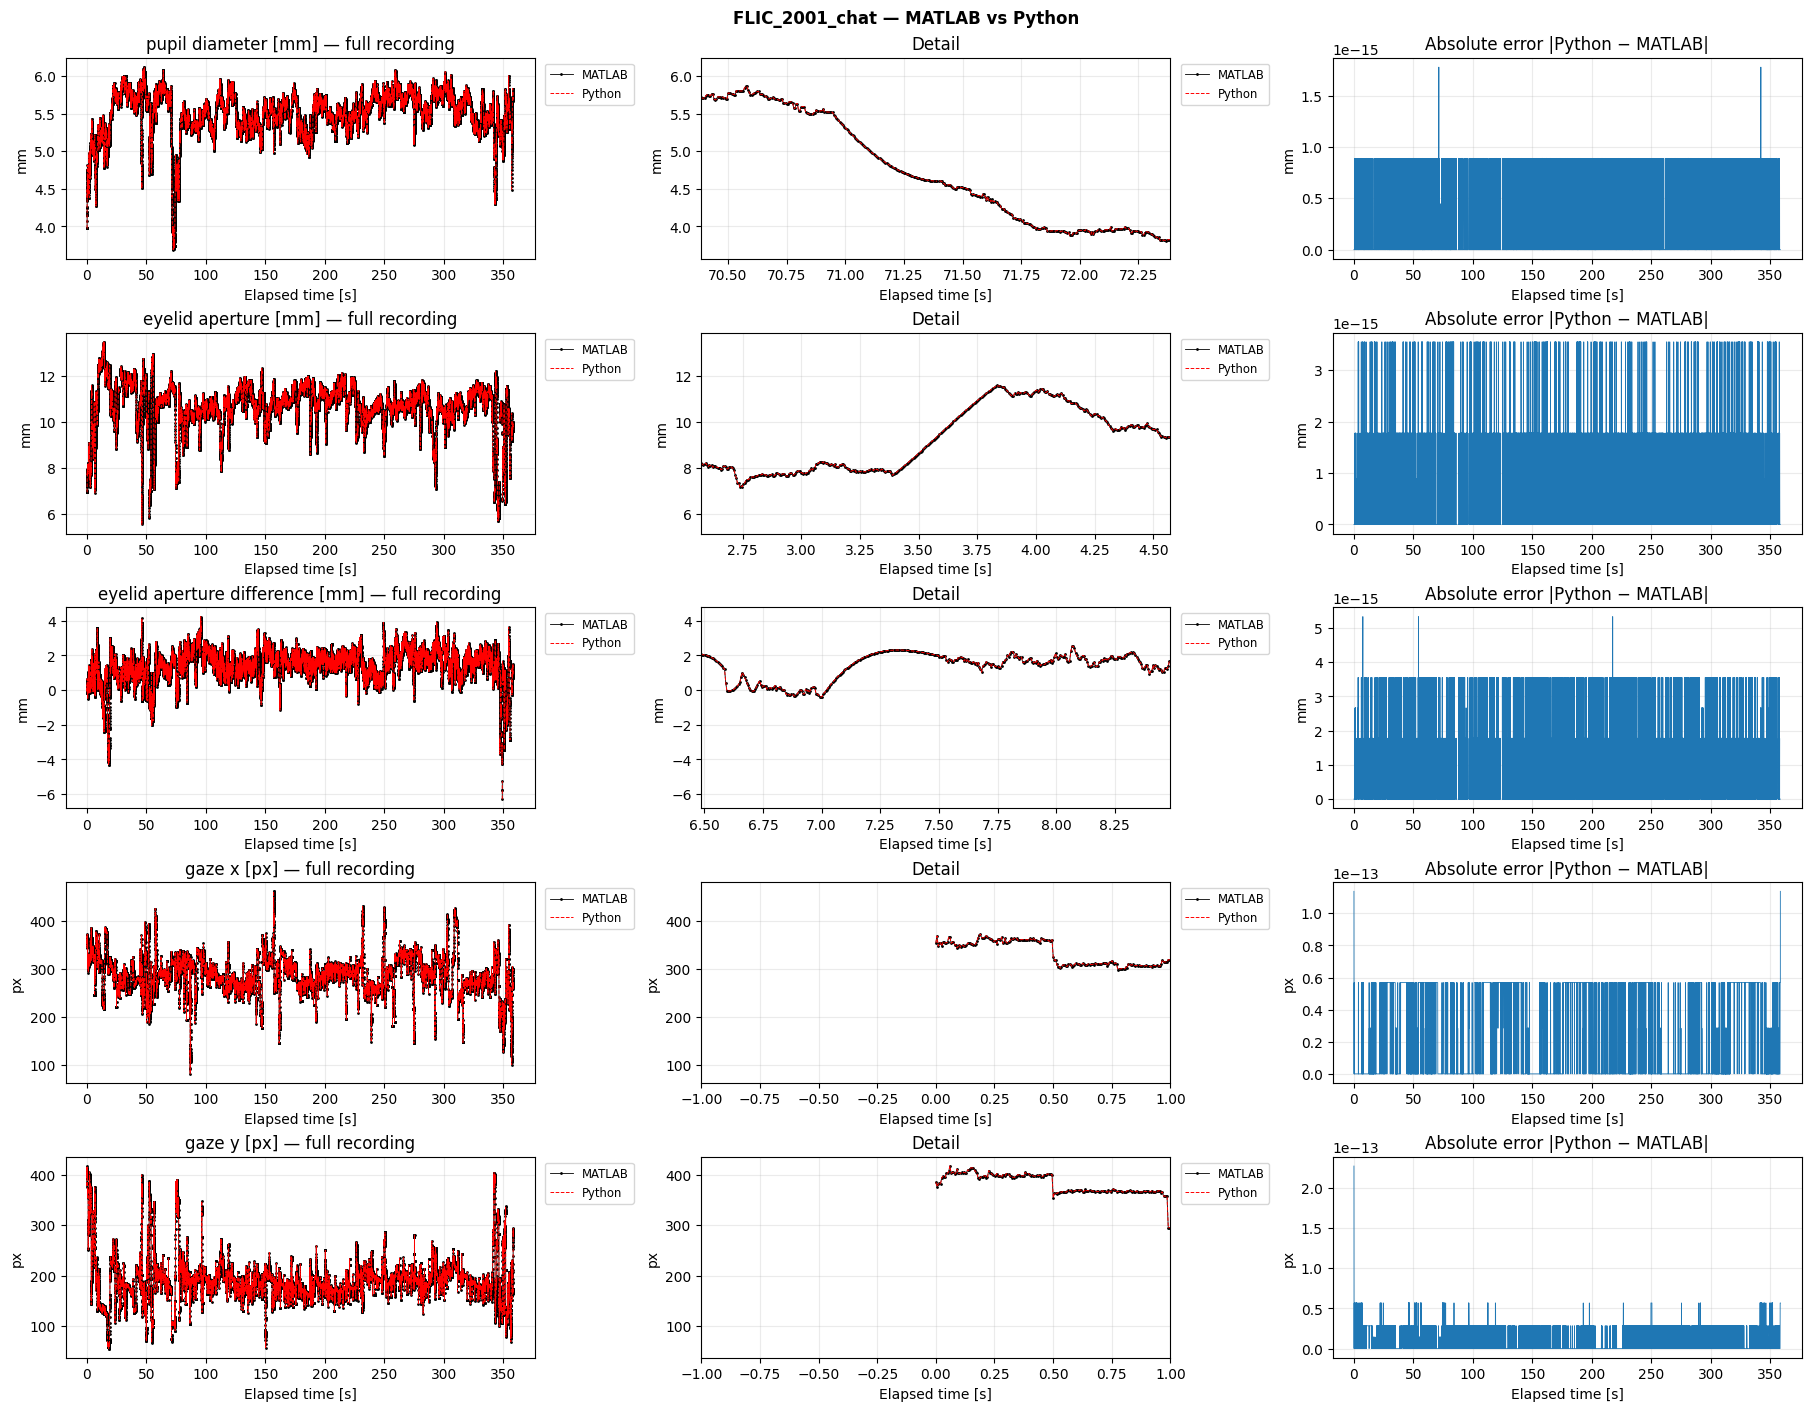

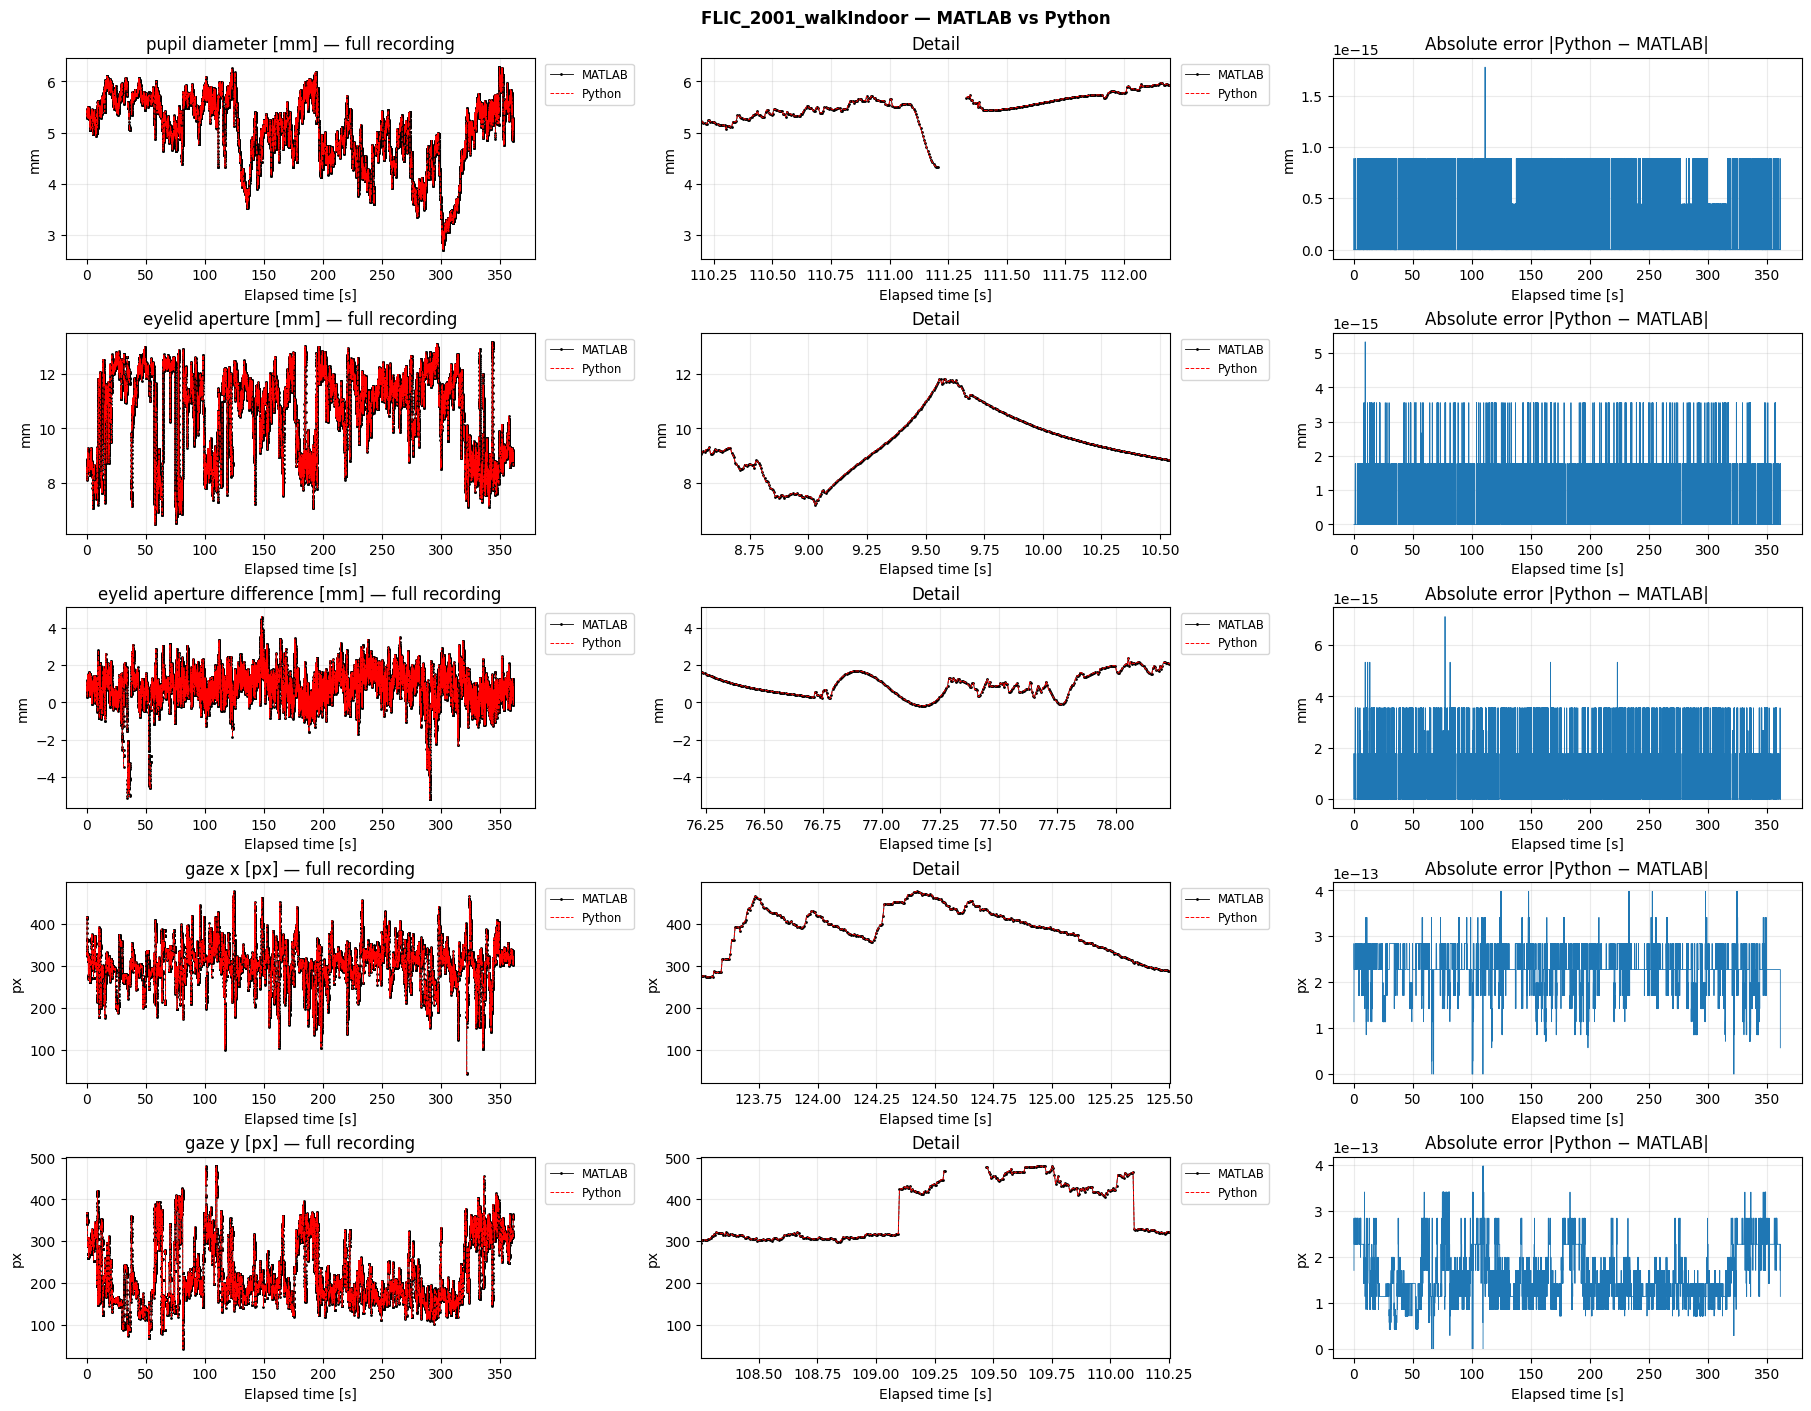

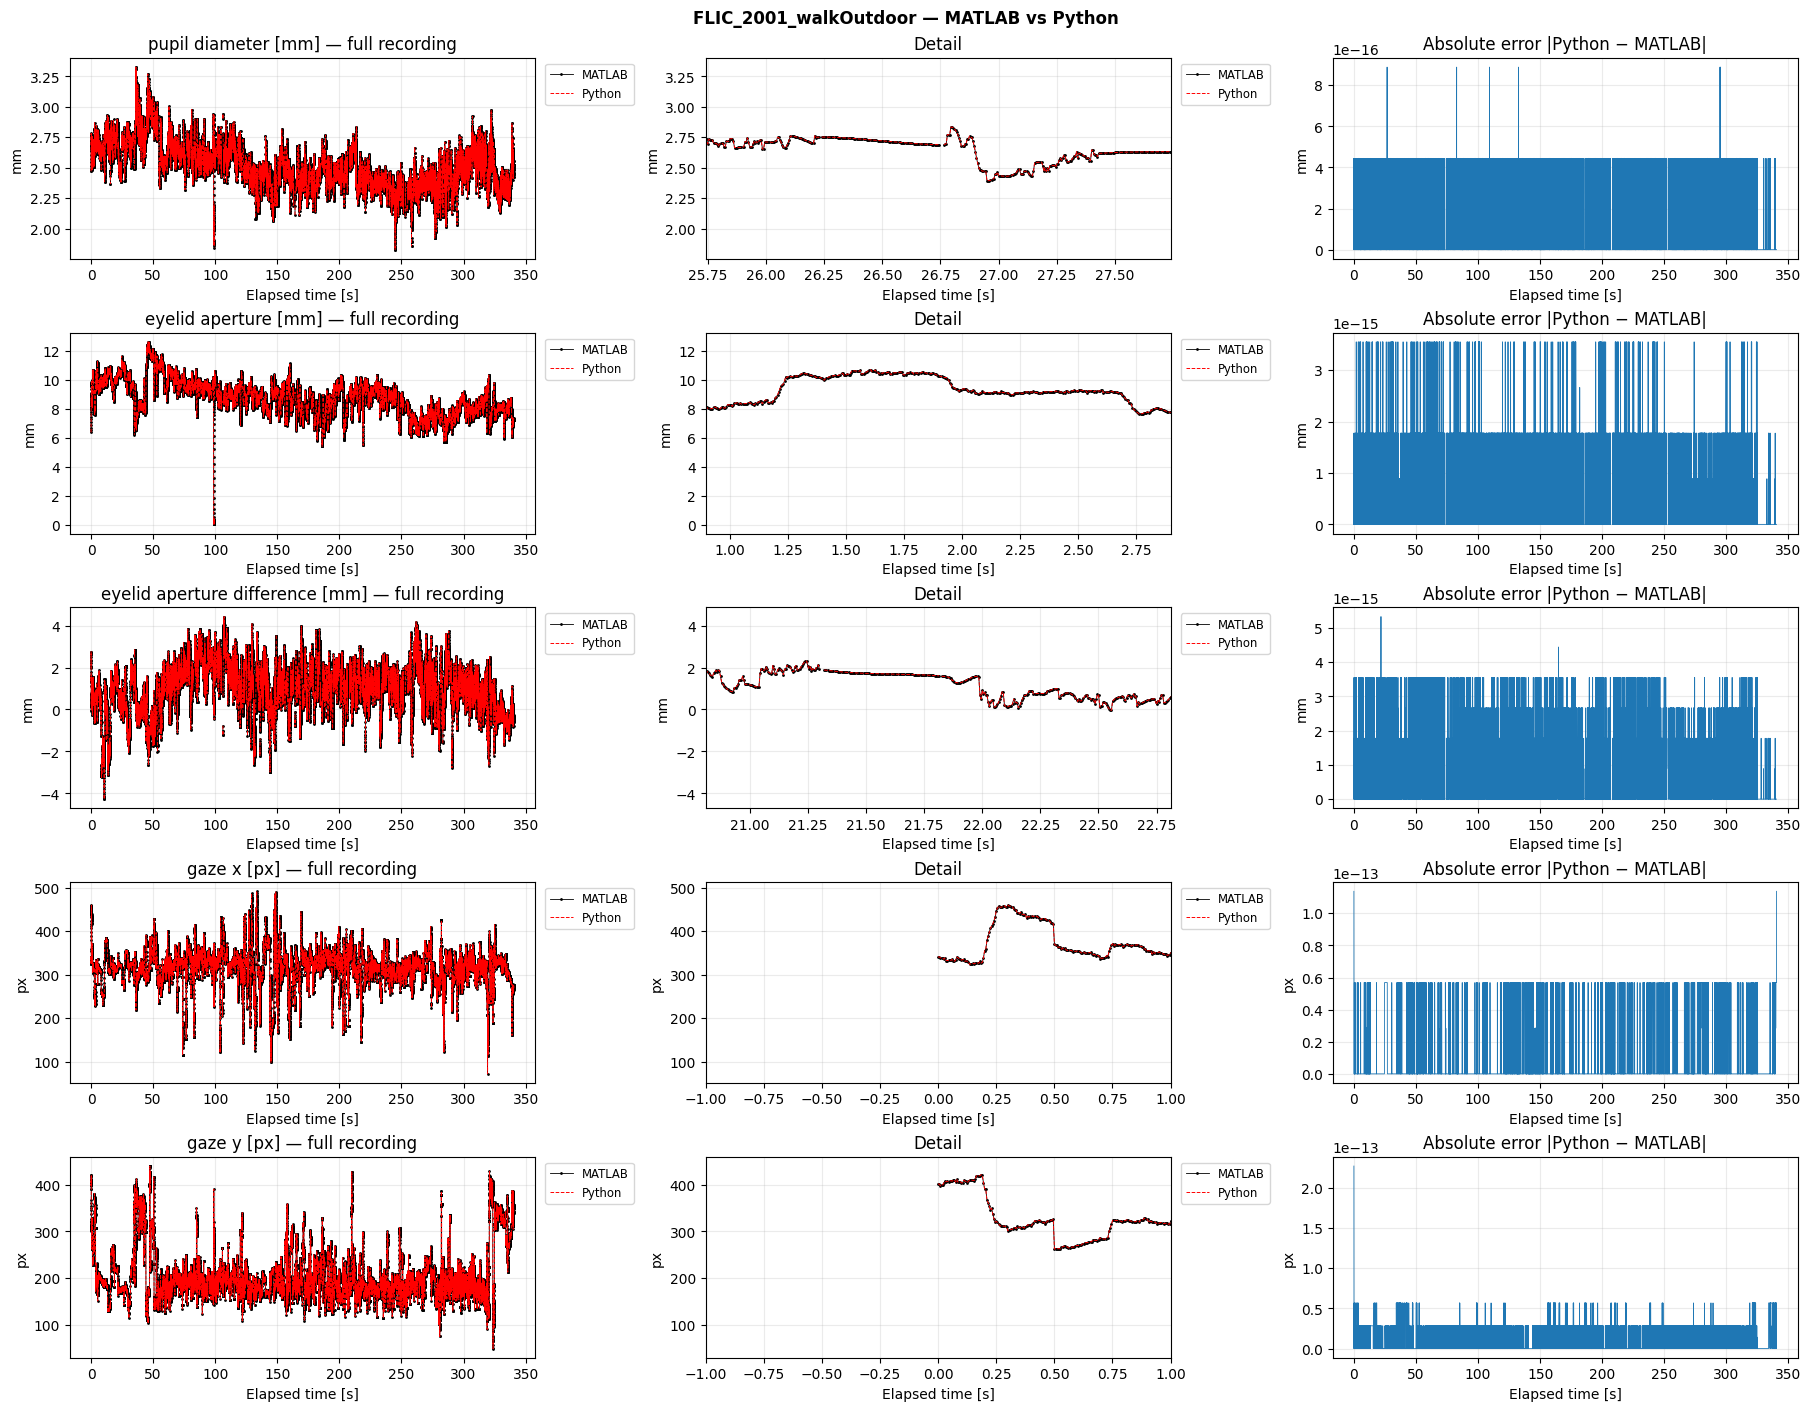

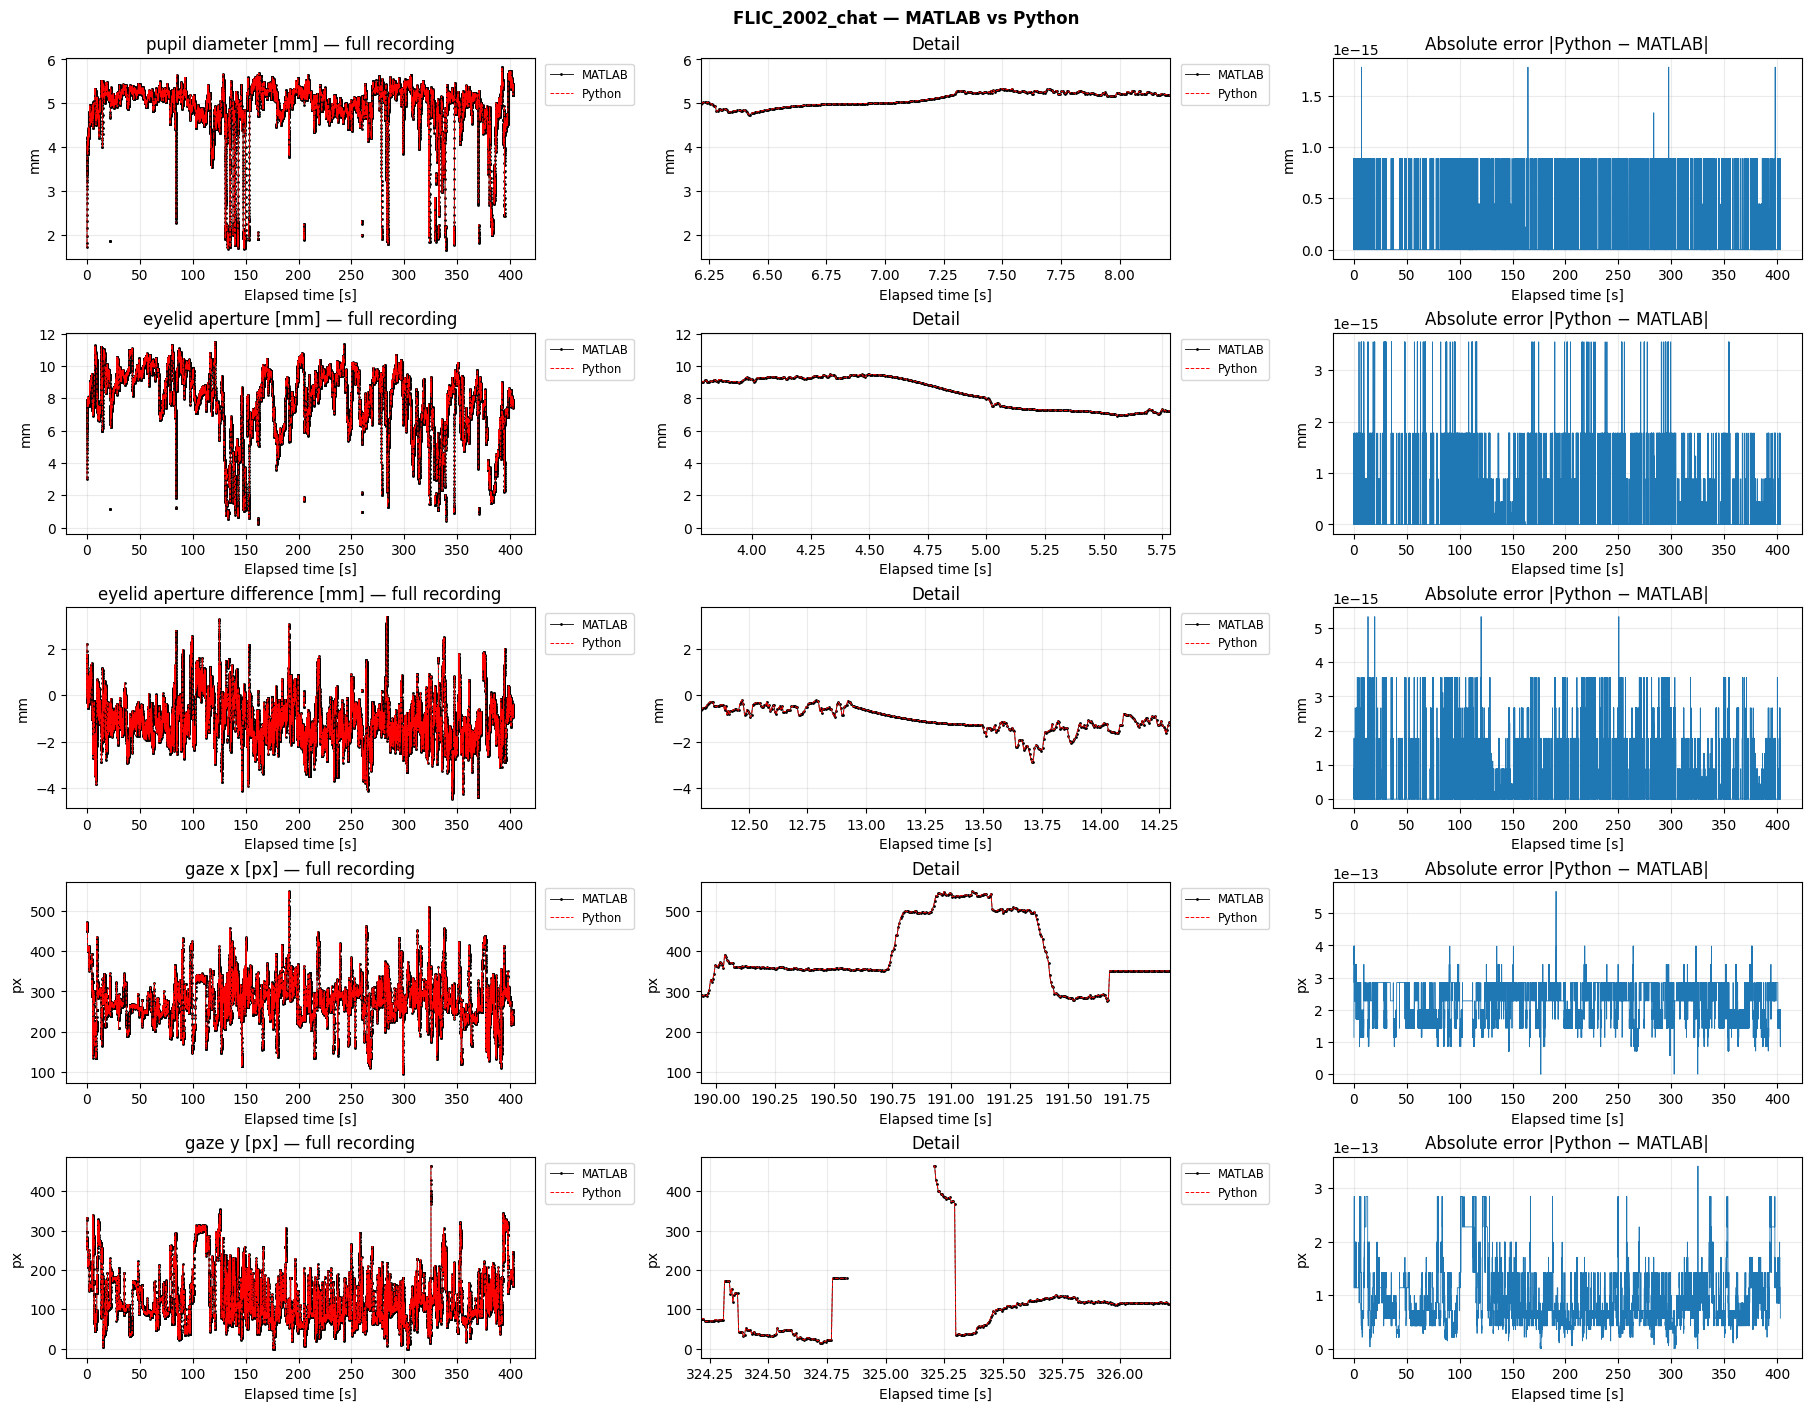

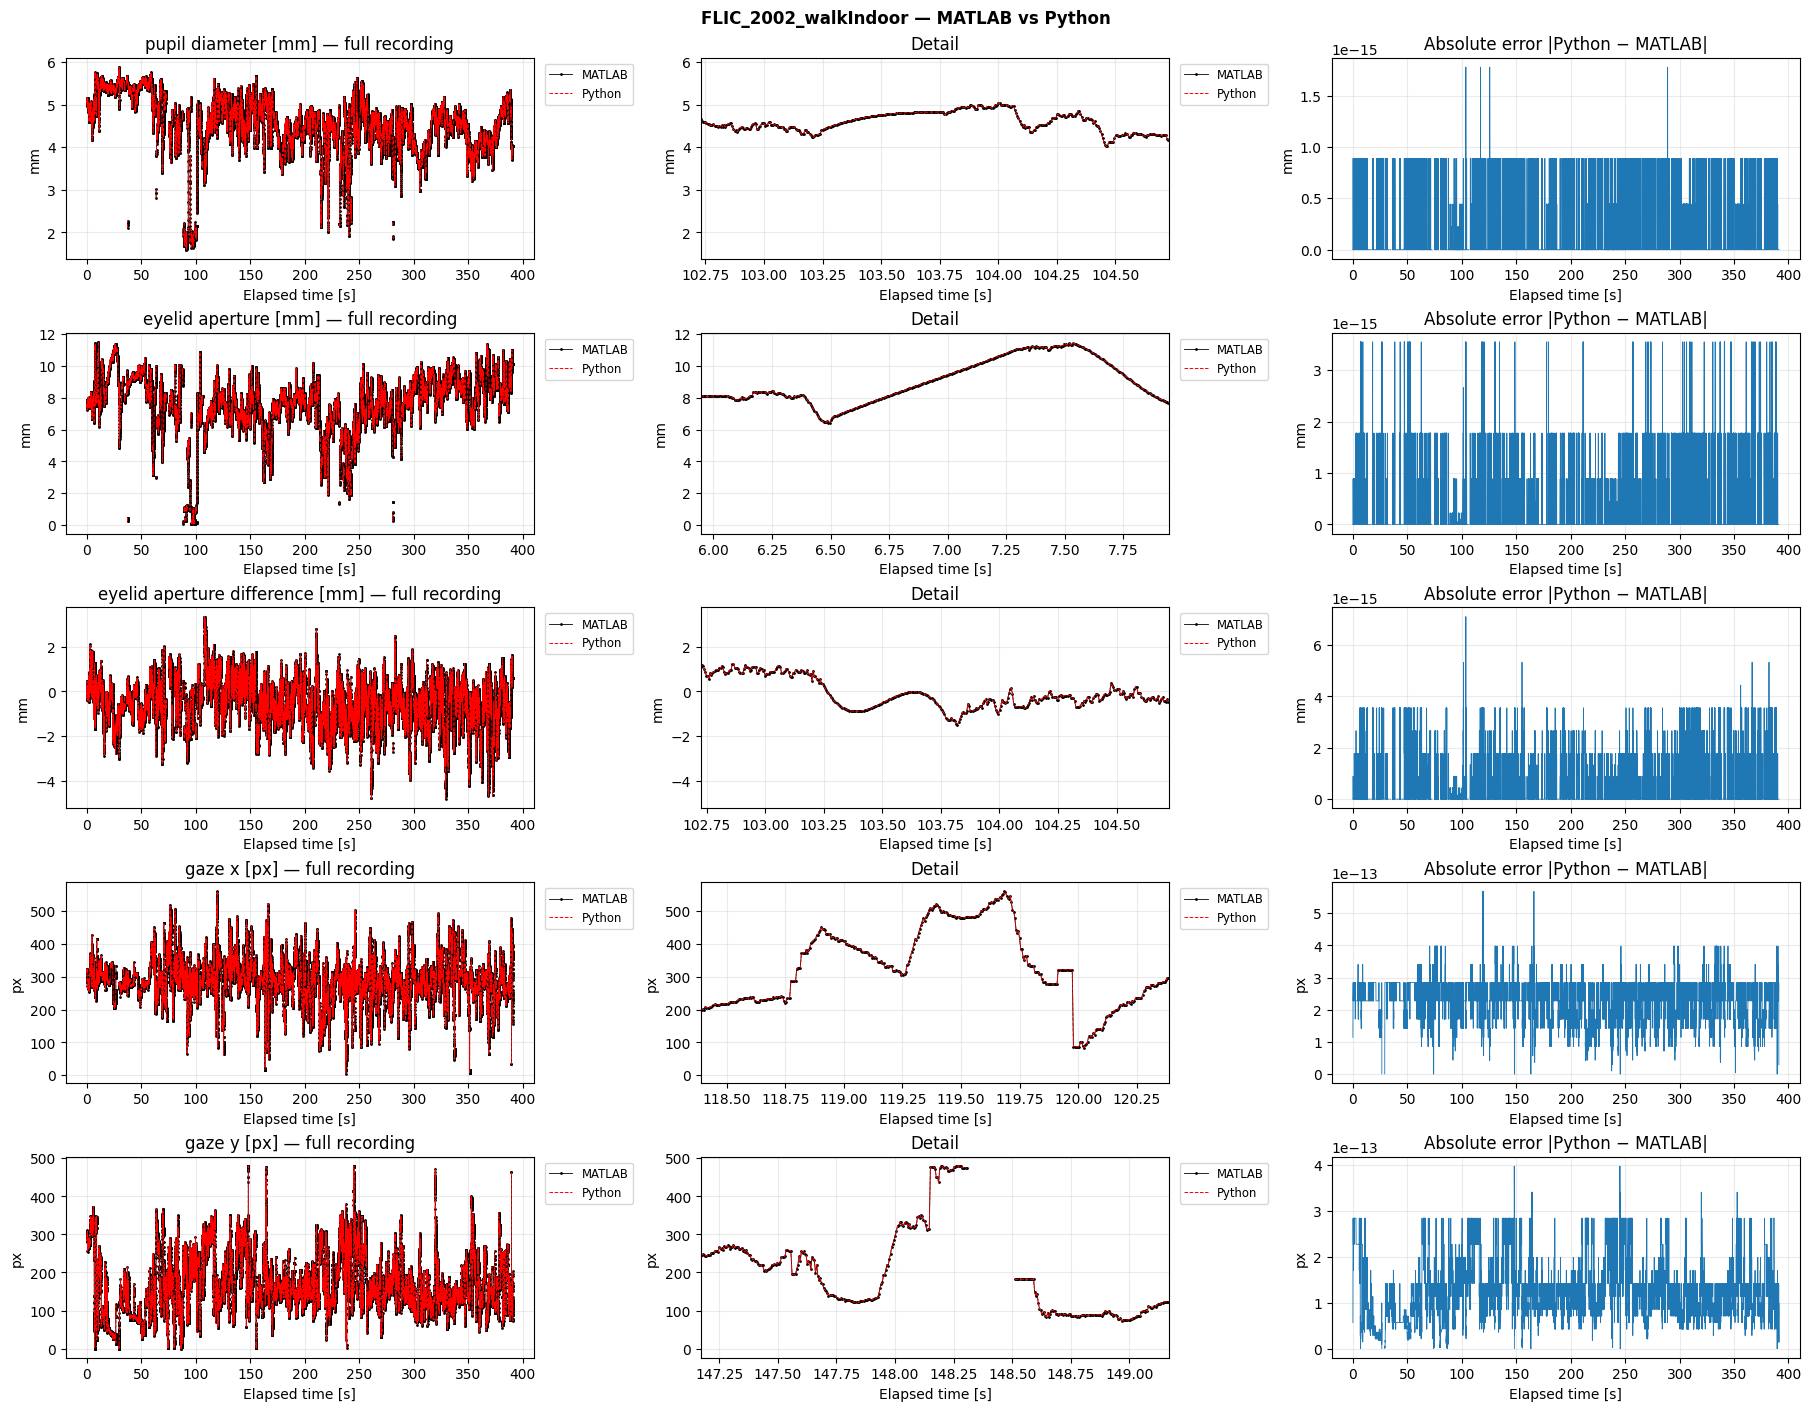

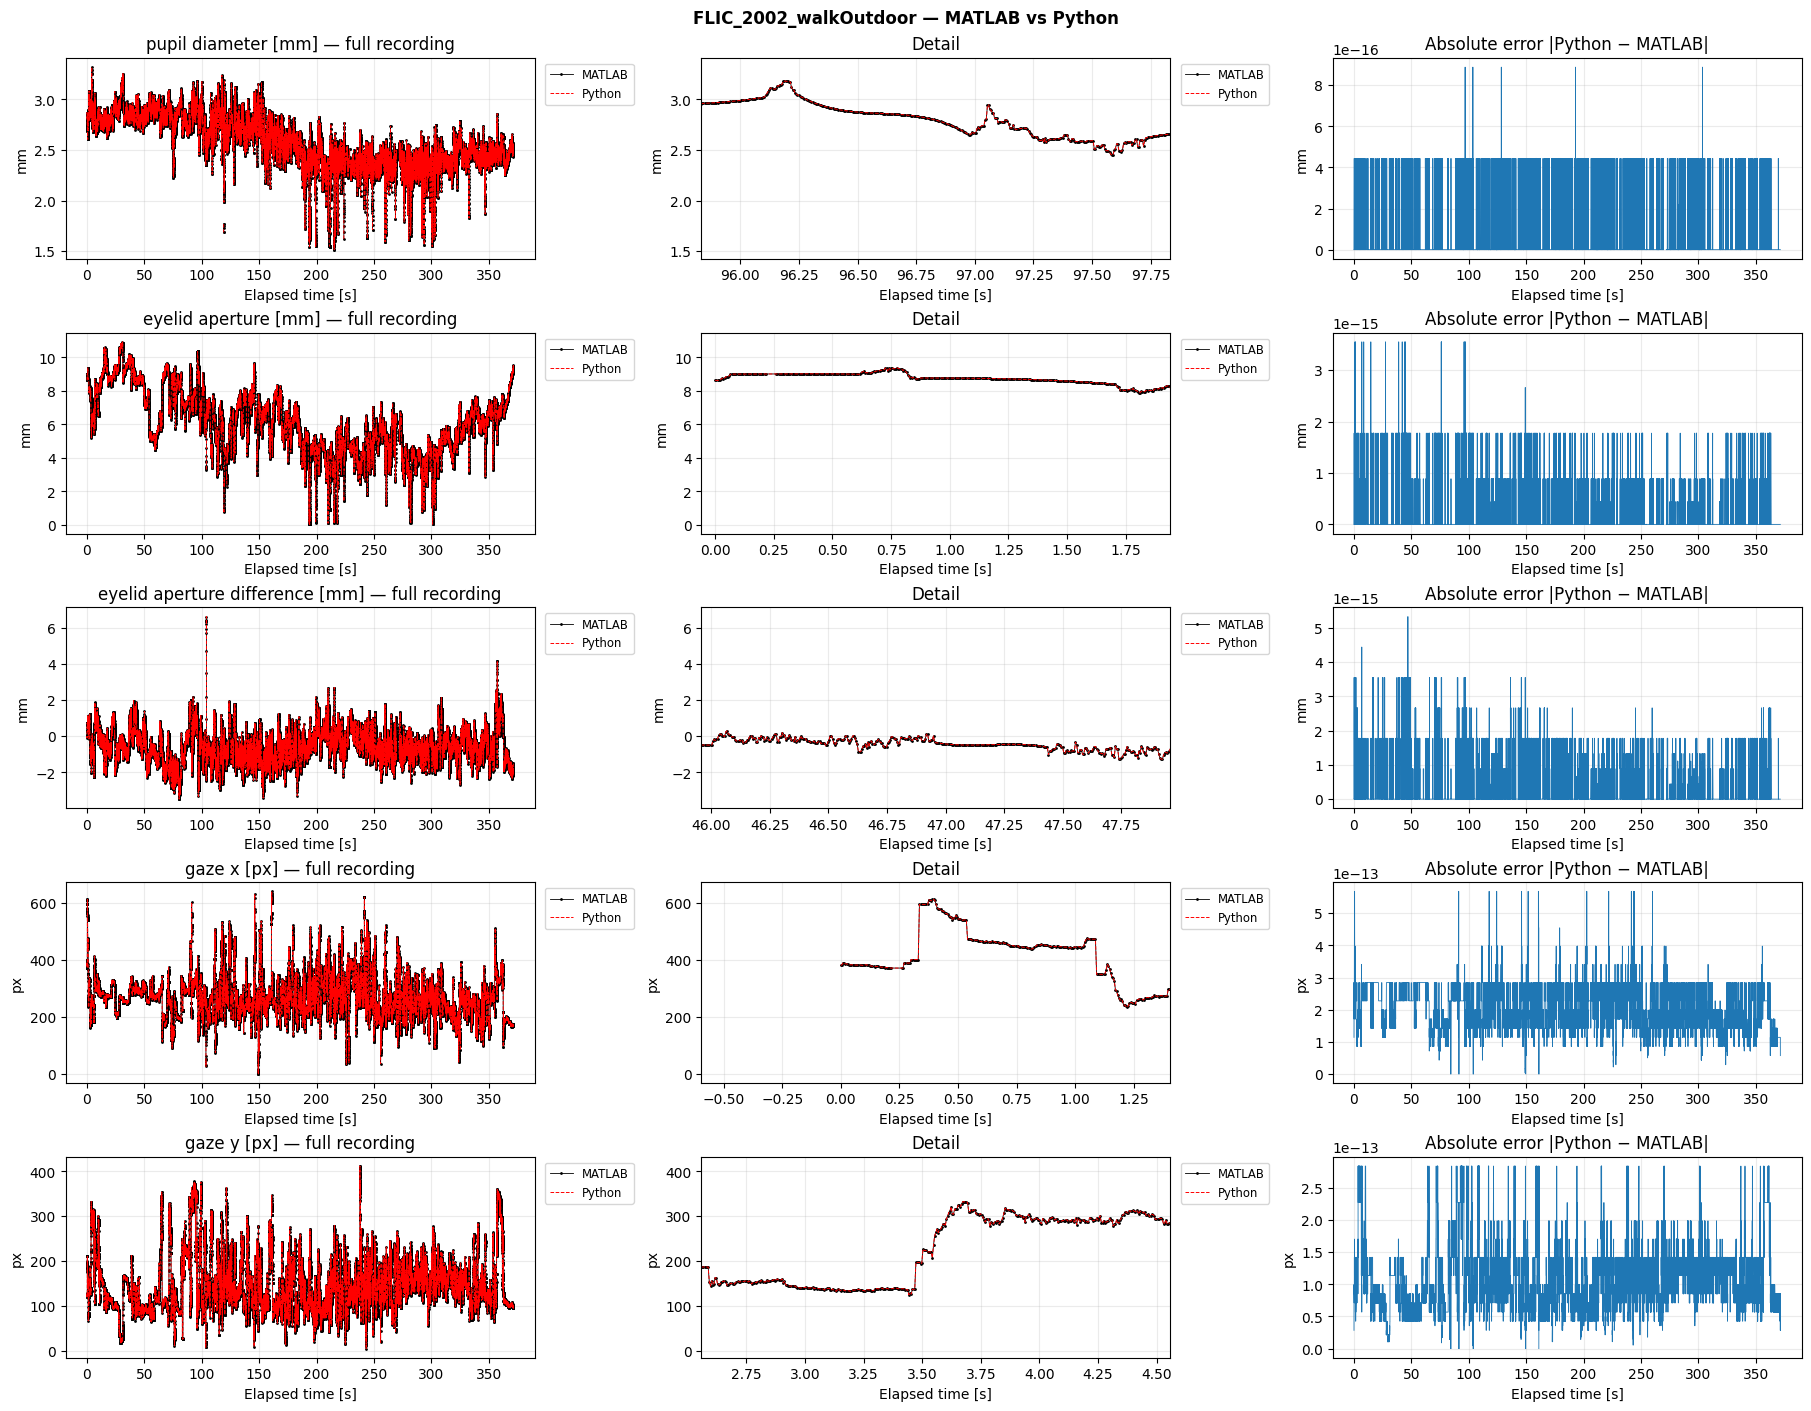

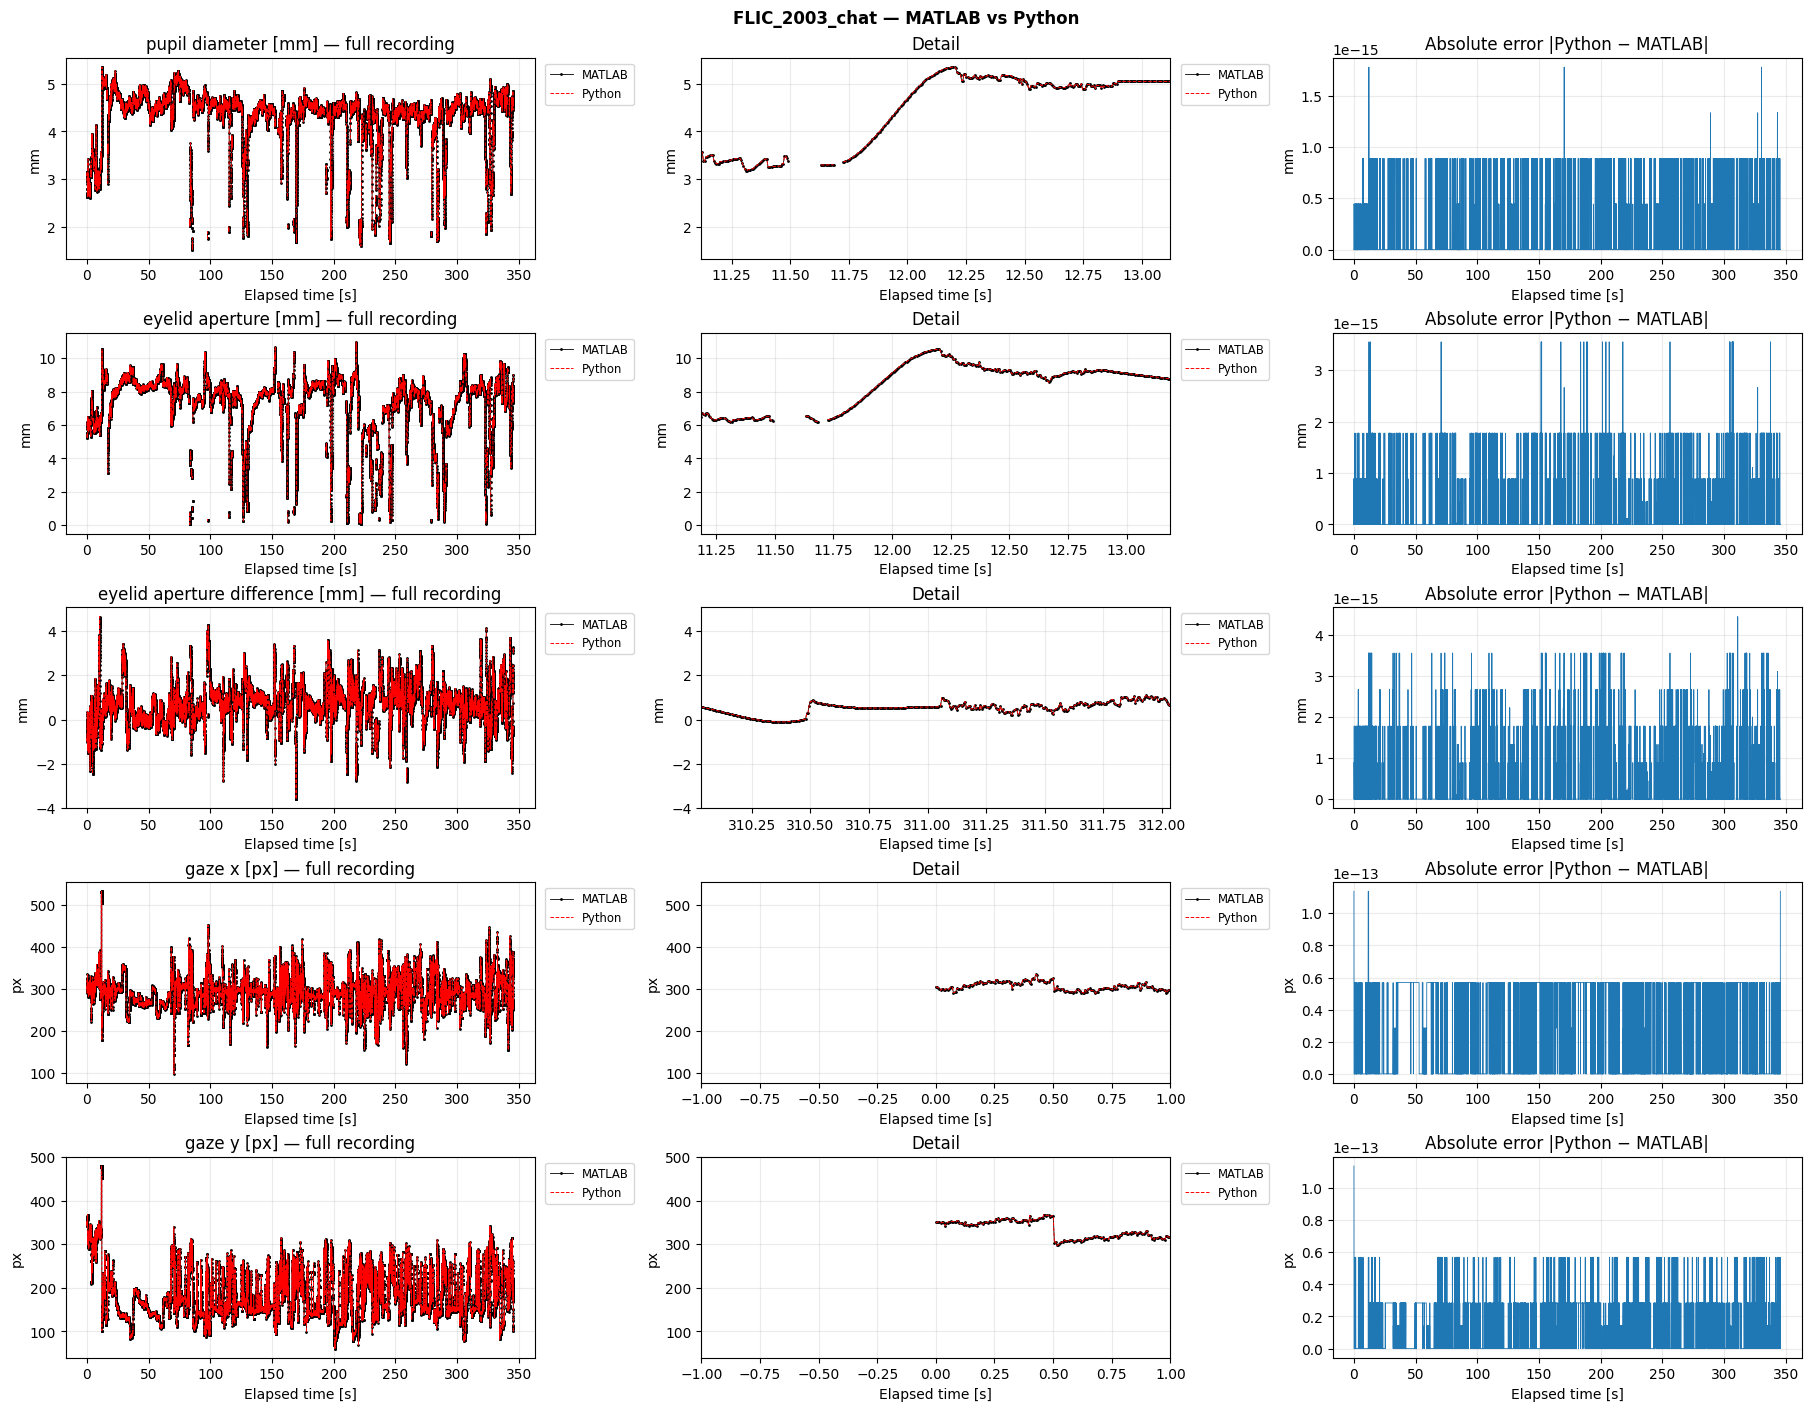

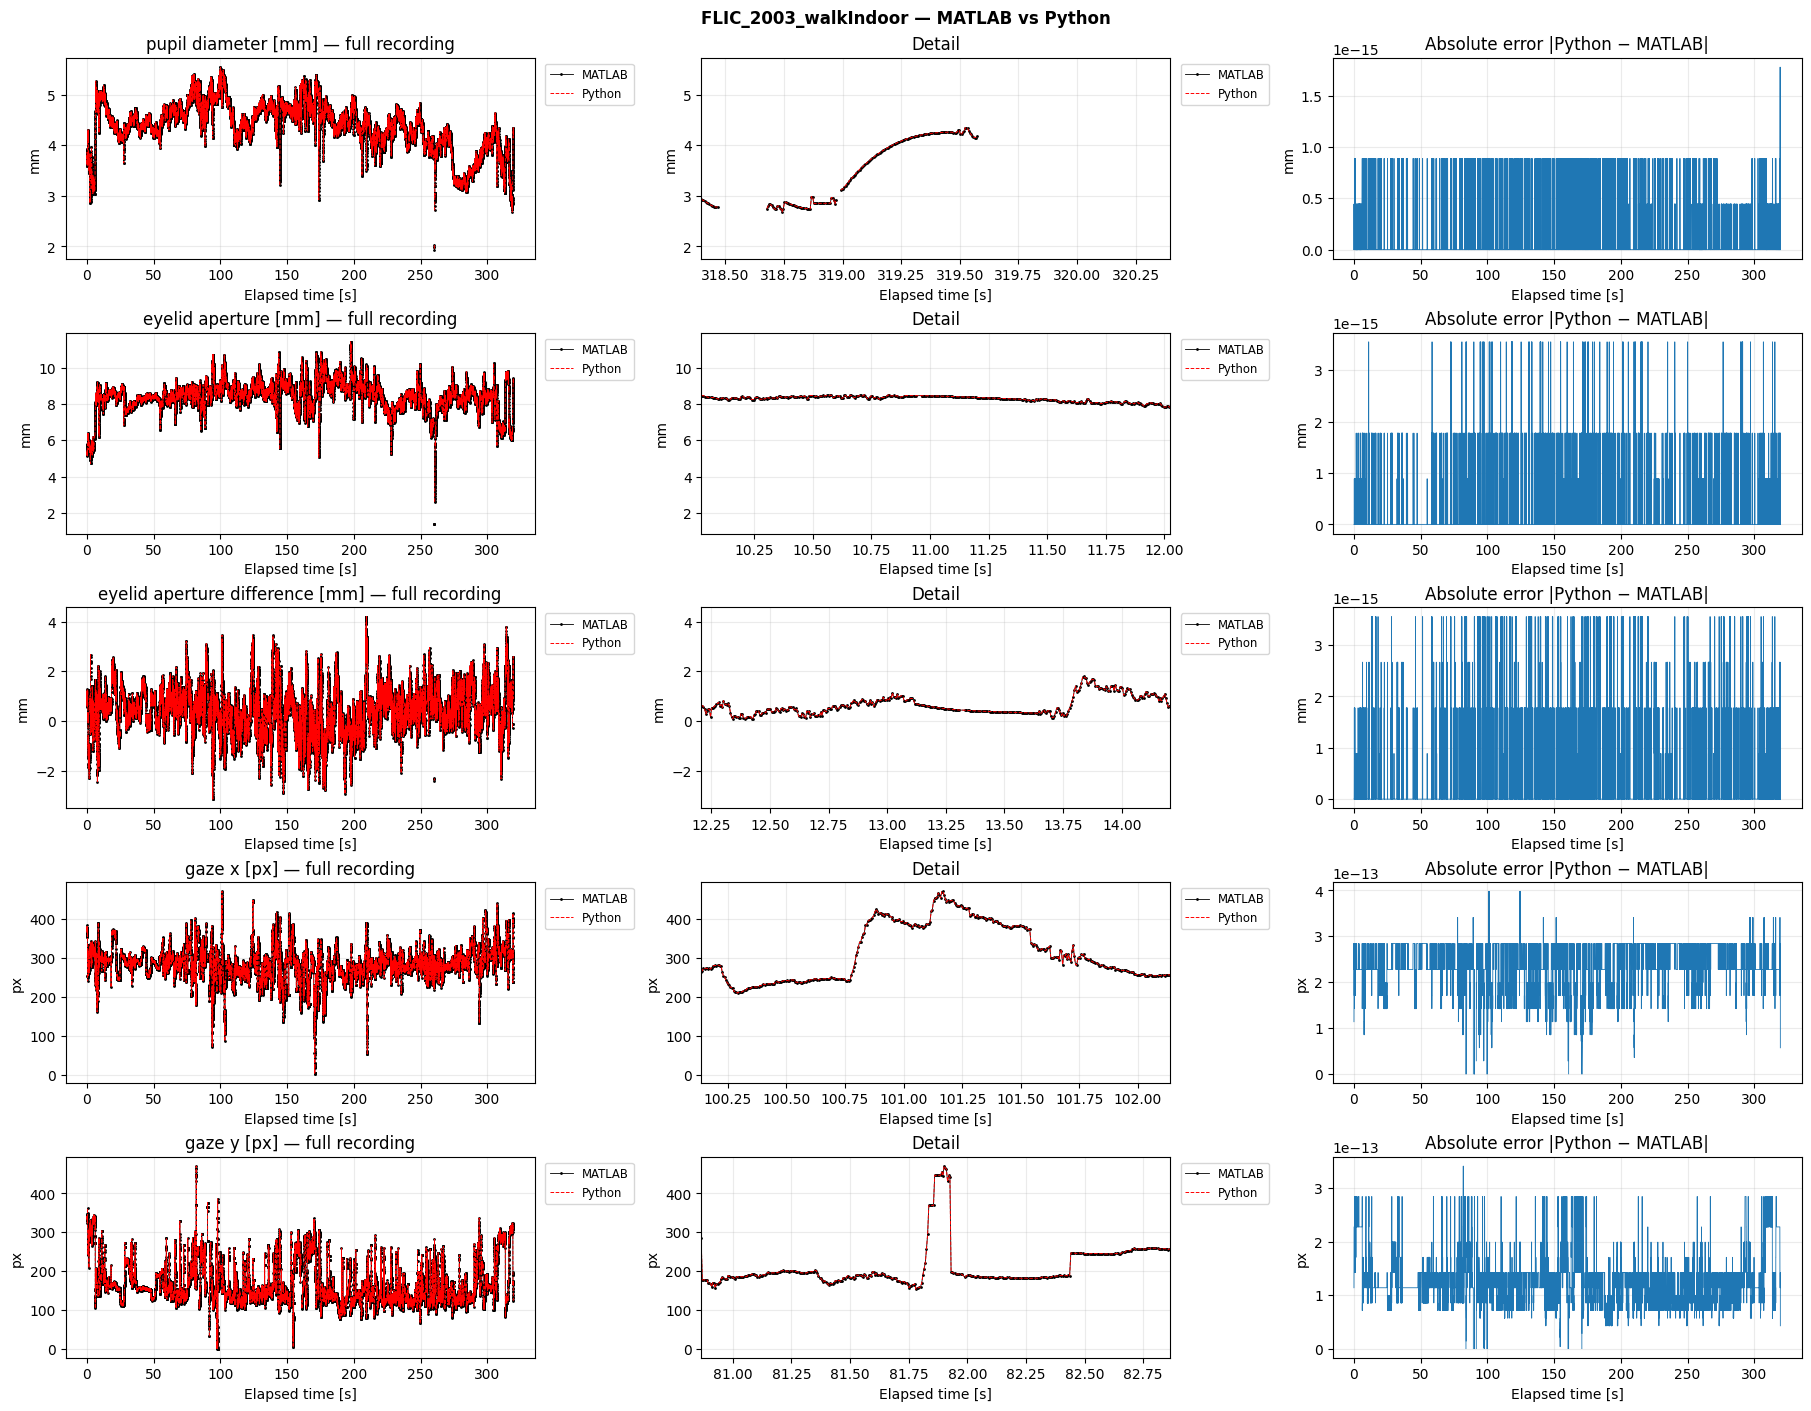

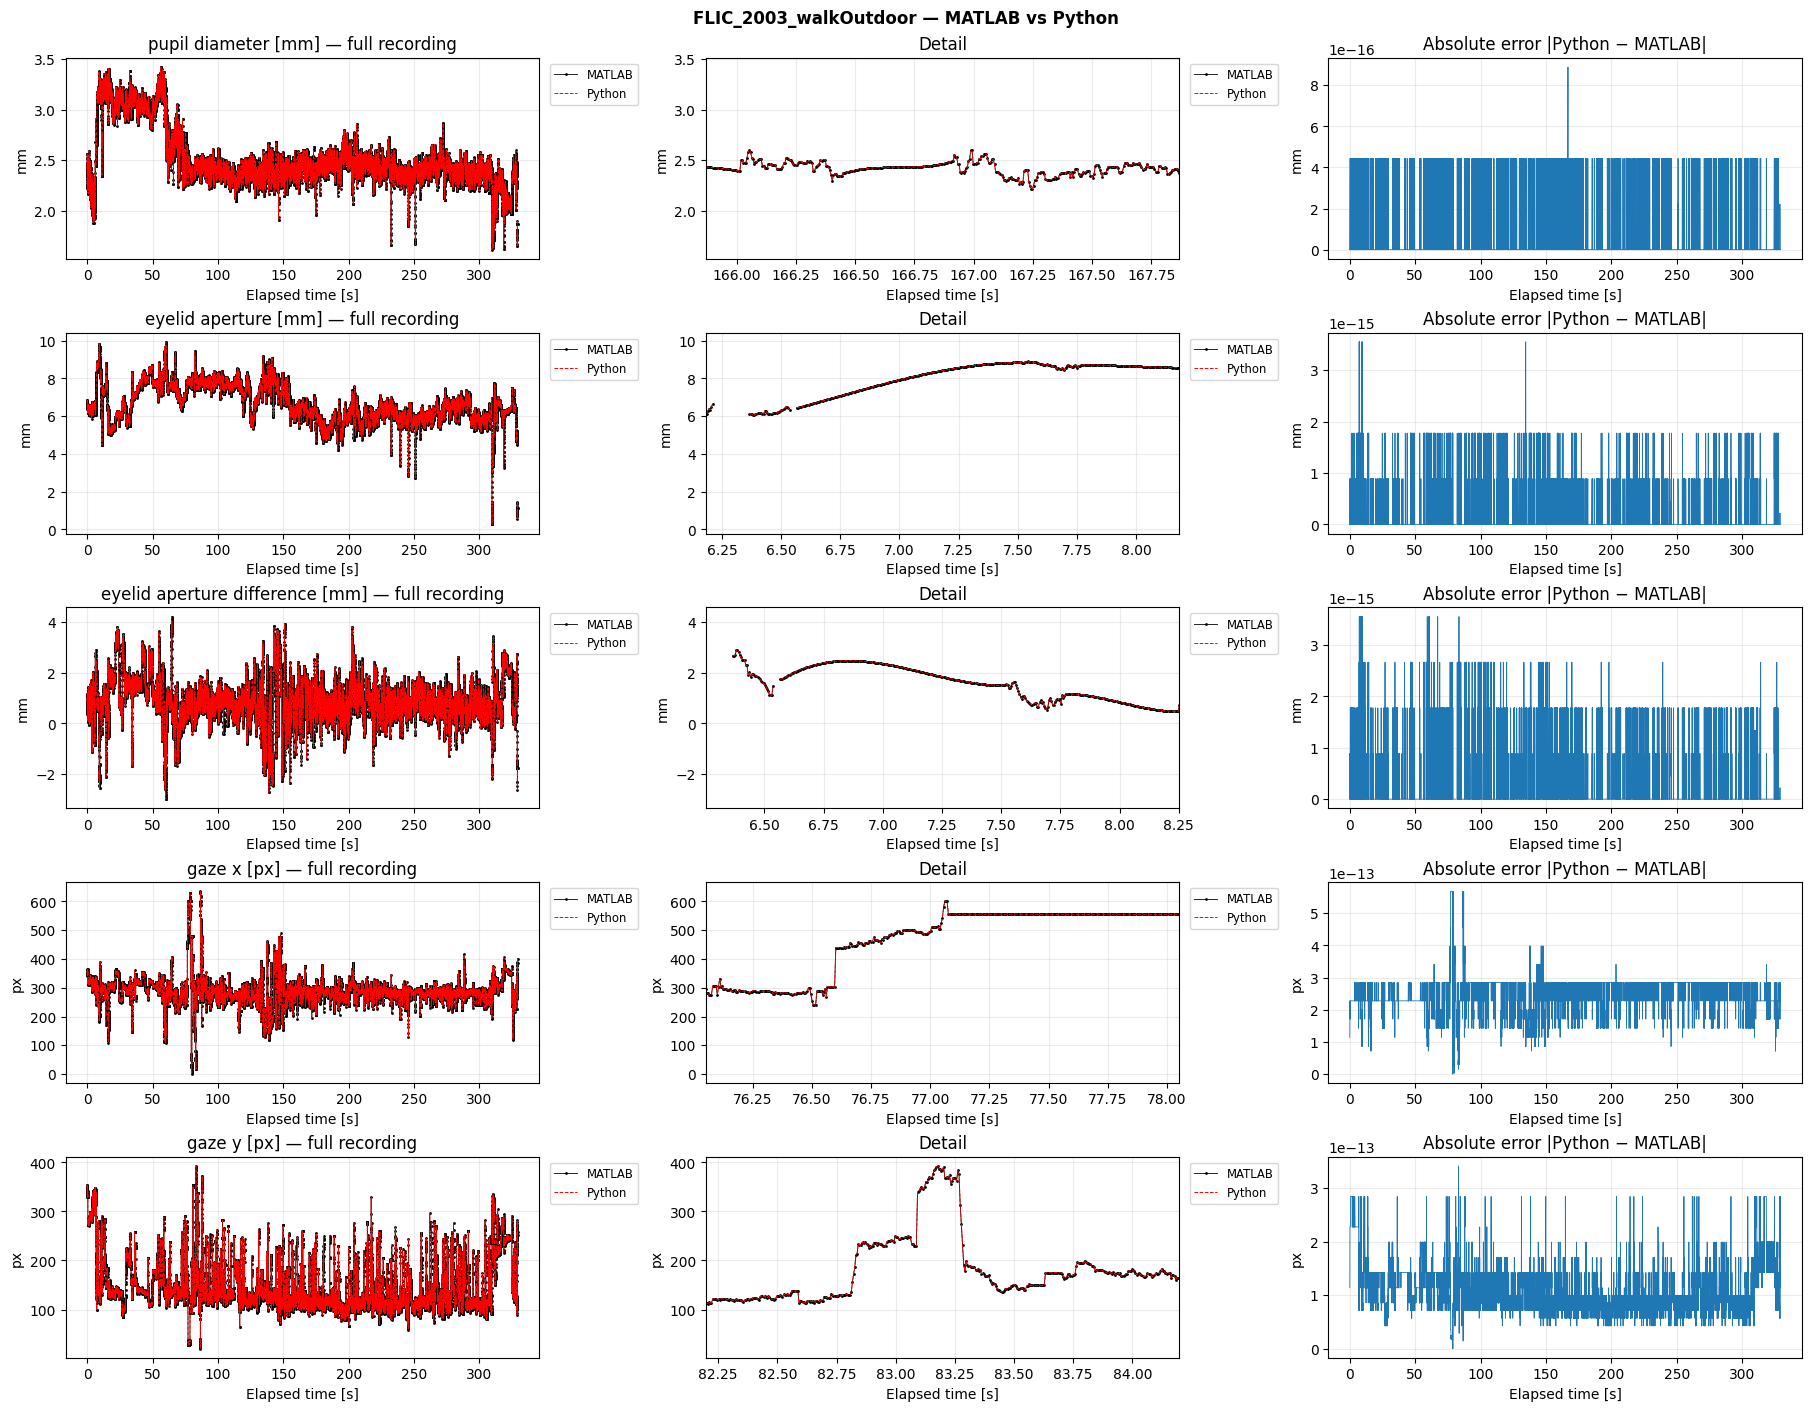

In [5]:
# Define the column order returned by both cleaners.
output_columns: tuple[str, ...] = (
    "time [s]",
    "pupil diameter [mm]",
    "eyelid aperture [mm]",
    "eyelid aperture difference [mm]",
    "gaze x [px]",
    "gaze y [px]",
)

time_column: int = output_columns.index("time [s]")
measurement_columns: tuple[str, ...] = output_columns[1:]


# Calculate the mean and maximum absolute error for each recording.
comparison_rows: list[dict] = []

for recording in recordings:
    recording_name: str = recording["recording_name"]

    # Get the two outputs for this recording. Each row is a sample and each
    # column is one of the measurements named above.
    matlab_data: np.ndarray = matlab_results[recording_name]["cleaned_data_matrix"]
    python_data: np.ndarray = python_results[recording_name]

    # Compare corresponding rows without resampling either output. Both arrays
    # must have the same dimensions for this comparison to make sense.
    assert matlab_data.shape == python_data.shape, f"{recording_name}: output shapes differ."
    assert matlab_data.shape[1] == len(output_columns), "Unexpected output column count."

    for column_index, column_name in enumerate(output_columns):
        matlab_values: np.ndarray = matlab_data[:, column_index]
        python_values: np.ndarray = python_data[:, column_index]

        # Keep only samples where both outputs contain a finite value.
        # Missing values and infinities cannot contribute to a numerical mean.
        valid_pair_mask: np.ndarray = np.isfinite(matlab_values) & np.isfinite(python_values)
        valid_matlab_values: np.ndarray = matlab_values[valid_pair_mask]
        valid_python_values: np.ndarray = python_values[valid_pair_mask]

        # Take the magnitude of each difference so positive and negative
        # differences do not cancel when averaged.
        absolute_errors: np.ndarray = np.abs(valid_python_values - valid_matlab_values)
        valid_pair_count: int = len(absolute_errors)

        # Leave both summaries as NaN if there are no samples to compare.
        # Zero would incorrectly suggest that the two outputs agree.
        mean_absolute_error: float = np.nan
        maximum_absolute_error: float = np.nan

        if valid_pair_count > 0:
            mean_absolute_error = float(np.mean(absolute_errors))
            maximum_absolute_error = float(np.max(absolute_errors))

        # Keep the sample counts alongside the errors so it is clear how much
        # of this measurement was actually included in the comparison.
        comparison_rows.append({
            "recording": recording_name,
            "signal": column_name,
            "samples": len(matlab_values),
            "finite_pairs": valid_pair_count,
            "max_absolute_error": maximum_absolute_error,
            "mean_absolute_error": mean_absolute_error,
        })

# Display one row per recording and measurement, including the time column.
comparison_table: pd.DataFrame = pd.DataFrame(comparison_rows)

# Scientific notation keeps small differences visible instead of rounding
# them to zero in the displayed table. It does not change the stored values.
with pd.option_context("display.float_format", "{:.3e}".format):
    display(comparison_table)


# Plot the measurements and their differences for each recording.
zoom_duration_s: float = 2.0

for recording in recordings:
    recording_name: str = recording["recording_name"]
    matlab_data: np.ndarray = matlab_results[recording_name]["cleaned_data_matrix"]
    python_data: np.ndarray = python_results[recording_name]

    # Use each output's own timestamps for its measurement lines. The error
    # plot uses MATLAB's timestamps to locate the corresponding row differences.
    matlab_timestamps_s: np.ndarray = matlab_data[:, time_column]
    python_timestamps_s: np.ndarray = python_data[:, time_column]

    # Keep the close-up no wider than the recording. Calculate this once here
    # because all measurements in the recording use the same time range.
    half_zoom_duration_s: float = zoom_duration_s / 2

    if len(matlab_timestamps_s) > 1:
        recording_duration_s: float = matlab_timestamps_s[-1] - matlab_timestamps_s[0]
        half_zoom_duration_s = min(half_zoom_duration_s, recording_duration_s / 2)

    # Give each measurement three panels: the full recording, a close-up,
    # and the absolute error. squeeze=False keeps axes as a two-dimensional array.
    figure, axes = plt.subplots(
        len(measurement_columns), 3,
        figsize=(18, 14),
        constrained_layout=True,
        squeeze=False,
    )
    figure.suptitle(f"{recording_name} — MATLAB vs Python", fontweight="bold")

    for row_index, column_name in enumerate(measurement_columns):
        column_index: int = output_columns.index(column_name)
        matlab_values: np.ndarray = matlab_data[:, column_index]
        python_values: np.ndarray = python_data[:, column_index]

        # Keep the full-length error array for plotting so missing samples stay
        # at their original positions rather than shifting later values forward.
        absolute_errors: np.ndarray = np.abs(python_values - matlab_values)
        finite_error_mask: np.ndarray = np.isfinite(absolute_errors)
        finite_sample_indices: np.ndarray = np.where(finite_error_mask)[0]

        # If there are no finite errors, center the close-up on the recording.
        focus_sample_index: int = len(matlab_timestamps_s) // 2

        if len(finite_sample_indices) > 0:
            finite_absolute_errors: np.ndarray = absolute_errors[finite_sample_indices]
            largest_error_position: int = int(np.argmax(finite_absolute_errors))
            largest_absolute_error: float = float(finite_absolute_errors[largest_error_position])

            # If the outputs are identical, show the middle available sample.
            # Otherwise show where they differ most. These positions refer to
            # the filtered array, so map back to the original sample indices.
            focus_position: int = len(finite_sample_indices) // 2

            if largest_absolute_error > 0:
                focus_position = largest_error_position

            focus_sample_index = int(finite_sample_indices[focus_position])

        # Convert the chosen sample to the time limits for the close-up.
        focus_timestamp_s: float = float(matlab_timestamps_s[focus_sample_index])
        zoom_start_s: float = focus_timestamp_s - half_zoom_duration_s
        zoom_end_s: float = focus_timestamp_s + half_zoom_duration_s

        full_axis, detail_axis, difference_axis = axes[row_index]

        # Draw both outputs in the full and close-up panels. They contain the
        # same lines; only the close-up panel's time limits are restricted.
        for axis in (full_axis, detail_axis):
            axis.plot(
                matlab_timestamps_s, matlab_values,
                "k.-", linewidth=0.6, markersize=2, label="MATLAB",
            )
            axis.plot(
                python_timestamps_s, python_values,
                "r--", linewidth=0.7, label="Python",
            )
            axis.legend(loc="upper left", bbox_to_anchor=(1.01, 1), fontsize="small")

        full_axis.set_title(f"{column_name} — full recording")
        detail_axis.set_title("Detail")
        detail_axis.set_xlim(zoom_start_s, zoom_end_s)

        # Show errors on their own scale so small differences remain visible
        # even when the two measurement lines appear to overlap completely.
        difference_axis.plot(
            matlab_timestamps_s, absolute_errors,
            color="tab:blue", linewidth=0.6,
        )
        difference_axis.set_title("Absolute error |Python − MATLAB|")

        # Label all three panels with the measurement's original units.
        measurement_units: str = "px" if column_name in ("gaze x [px]", "gaze y [px]") else "mm"

        for axis in axes[row_index]:
            axis.set_xlabel("Elapsed time [s]")
            axis.set_ylabel(measurement_units)
            axis.grid(alpha=0.25)

    # Keep the figure in the notebook output, then release the open plot window.
    display(figure)
    plt.close(figure)
